# MS11 — Détection d'anomalies · Notebook 04 (CRISP-DM)

Repérer les **trajets anormaux** (incidents) par apprentissage **non supervisé** (Isolation Forest).
Dataset propre à MS11 avec **3 natures d'anomalie** (franc / contextuel / surcharge). Le label
`incident_type` sert **uniquement à évaluer**. Palette **accessible aux daltoniens** (Okabe-Ito).

**Plan :** données → **EDA détaillée** → **visualiser le modèle non supervisé** → benchmark → gel.

**Étape 0 — Environnement & palette.**

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
while os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import IsolationForest
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.grid": True,
                     "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
os.makedirs("notebooks/figures", exist_ok=True)
FIG = "notebooks/figures"

# Palette accessible (daltonisme) — Okabe-Ito pour les catégories
NORMAL, INCIDENT = "#4C72B0", "#C44E52"
OKABE = {"panne": "#E69F00", "accident": "#D55E00", "route_bloquee": "#CC79A7",
         "retard_contextuel": "#009E73", "surcharge": "#56B4E9", "none": "#B0B0B0"}
SEQ = "viridis"   # séquentiel (magnitude du score d'anomalie), perceptuellement uniforme + CVD-safe

def clip(a, lo=1, hi=99):
    return np.percentile(a, lo), np.percentile(a, hi)

from config import settings
print("Répertoire :", os.getcwd())

Répertoire : C:\Users\Anass\Desktop\SDIA\S9\PFE\transport-scolaire\ms11-analytique


**Étape 1 — Données.** Génération si absent, puis chargement. On prépare aussi la matrice de features et le taux d'anomalies.

In [2]:
from features import label_binaire, build, CURATED, colonnes_all
if not os.path.exists(settings.dataset_path):
    import dataset_anomaly
    dataset_anomaly.generer().to_csv(settings.dataset_path, index=False)
df = pd.read_csv(settings.dataset_path)
y = label_binaire(df).to_numpy()
F = build(df)
contam = float(max(0.01, y.mean()))
print("Trajets :", len(df), "| incidents :", int(y.sum()), f"({100*y.mean():.2f}%) | contamination={contam:.3f}")

Trajets : 4320 | incidents : 54 (1.25%) | contamination=0.013


## A. EDA détaillée
**A1 — Répartition des types d'incident.** Combien de chaque nature ? (échelle log, valeurs annotées).

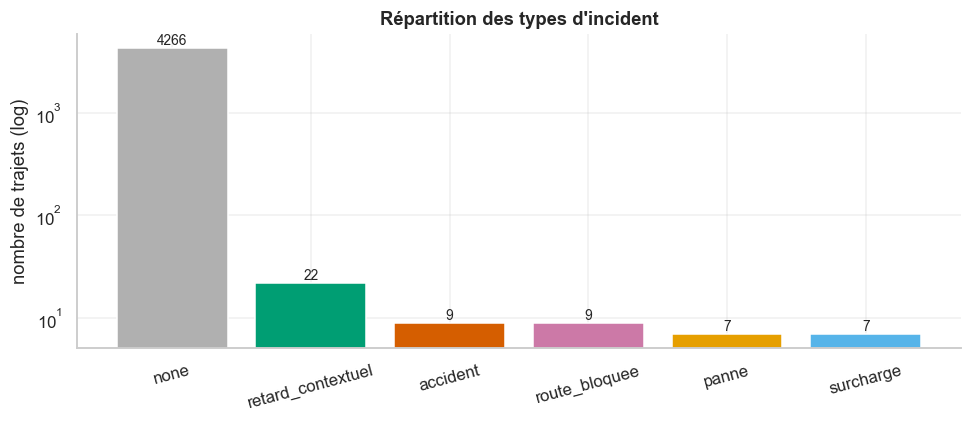

In [3]:
vc = df["incident_type"].value_counts()
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(vc.index, vc.values, color=[OKABE.get(k, "#999") for k in vc.index])
ax.set_yscale("log"); ax.set_ylabel("nombre de trajets (log)"); ax.set_title("Répartition des types d'incident")
for b, v in zip(bars, vc.values):
    ax.text(b.get_x() + b.get_width()/2, v, str(v), ha="center", va="bottom", fontsize=9)
plt.xticks(rotation=15); plt.tight_layout(); plt.savefig(f"{FIG}/04_types_incidents.png", bbox_inches="tight"); plt.show()

**A2 — Durée réelle par type d'incident.** Les incidents « francs » explosent la durée ; « contextuel » et « surcharge » sont bien plus discrets (d'où la difficulté).

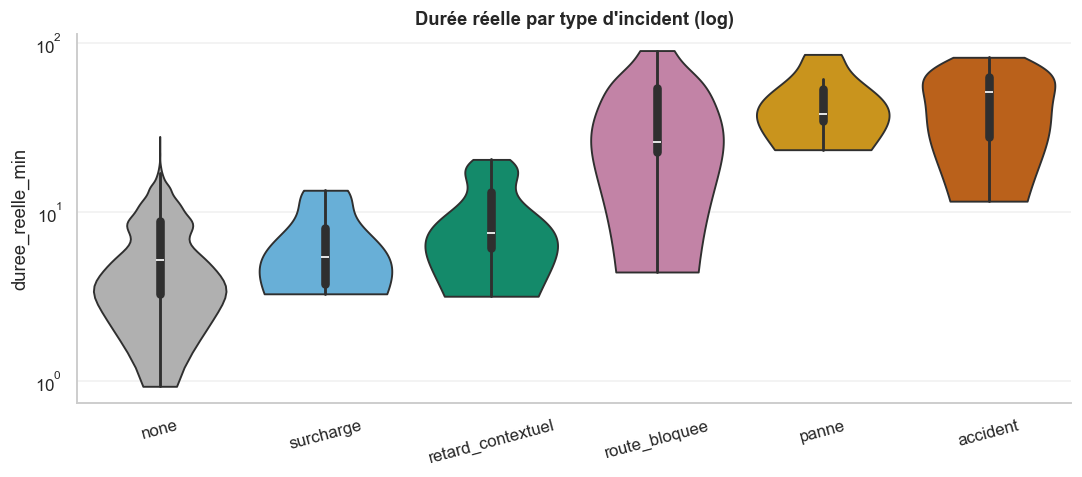

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
order = df.groupby("incident_type")["duree_reelle_min"].median().sort_values().index
sns.violinplot(data=df, x="incident_type", y="duree_reelle_min", order=order,
               palette=[OKABE.get(k, "#999") for k in order], cut=0, ax=ax)
ax.set_yscale("log"); ax.set_title("Durée réelle par type d'incident (log)"); ax.set_xlabel("")
plt.xticks(rotation=15); plt.tight_layout(); plt.savefig(f"{FIG}/04_duree_par_type.png", bbox_inches="tight"); plt.show()

**A3 — Distributions des 3 signaux clés** (normal vs incident, échelle log). `ratio` rate le contextuel ; `surprise` le récupère ; `dwell` isole la surcharge. **Aucun signal seul ne suffit.**

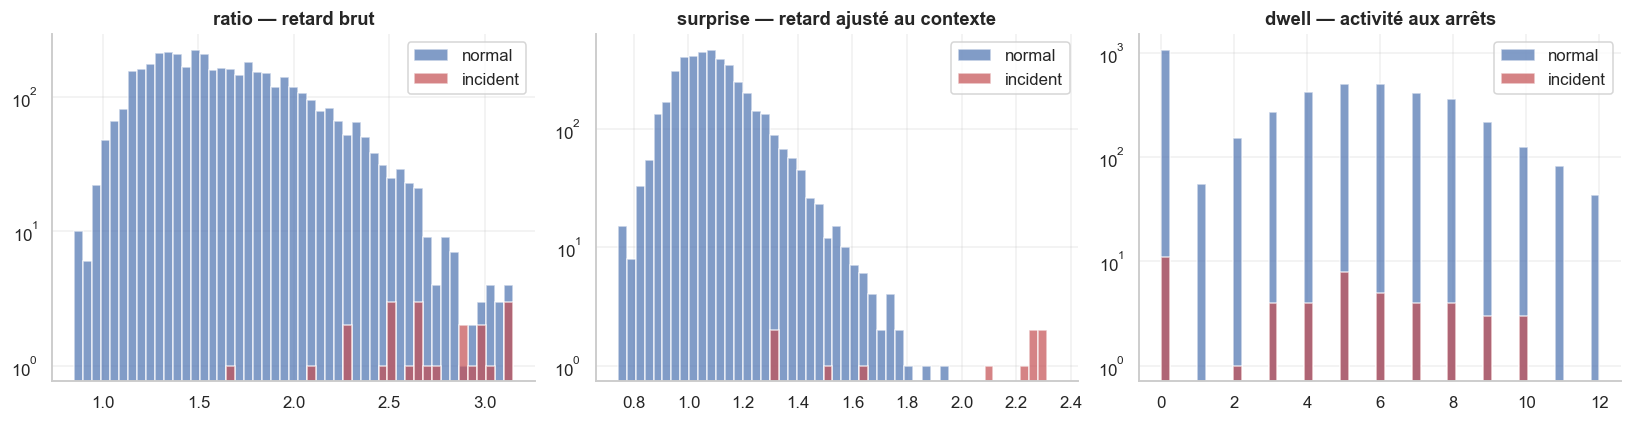

In [5]:
sig = [("ratio", "retard brut"), ("surprise", "retard ajusté au contexte"), ("dwell", "activité aux arrêts")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, sub) in zip(axes, sig):
    lo, hi = clip(F[col], 0, 99)
    bins = np.linspace(lo, hi, 50)
    ax.hist(F[col][y == 0], bins=bins, color=NORMAL, alpha=.7, label="normal")
    ax.hist(F[col][y == 1], bins=bins, color=INCIDENT, alpha=.7, label="incident")
    ax.set_yscale("log"); ax.set_title(f"{col} — {sub}"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/04_distributions_signaux.png", bbox_inches="tight"); plt.show()

**A4 — Corrélations des features curées.** Vue d'ensemble des dépendances (le `ratio` et la `surprise` sont liés mais pas identiques ; `dwell`/montées apportent une info orthogonale).

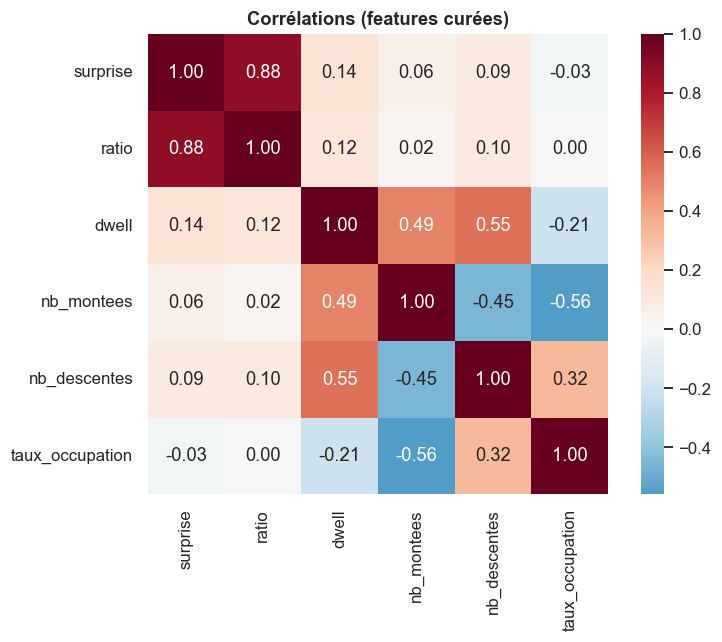

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(F[CURATED].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True, ax=ax)
ax.set_title("Corrélations (features curées)")
plt.tight_layout(); plt.savefig(f"{FIG}/04_correlations.png", bbox_inches="tight"); plt.show()

**A5 — Où vivent les anomalies ?** Nuage `surprise` × `ratio`, coloré par type. Les « francs » partent à droite (ratio), les « contextuels » montent en surprise, les « surcharges » restent près de l'origine (→ captées par `dwell`).

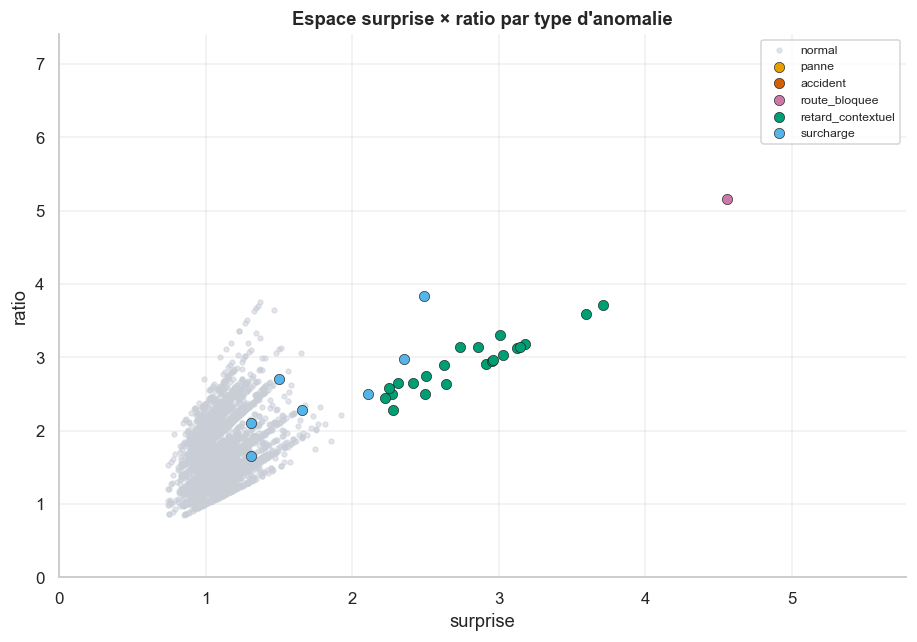

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 6))
norm = df["incident_type"] == "none"
ax.scatter(F["surprise"][norm], F["ratio"][norm], s=10, c="#C8CDD6", label="normal", alpha=.5)
for t in [k for k in OKABE if k != "none"]:
    m = df["incident_type"] == t
    if m.any():
        ax.scatter(F["surprise"][m], F["ratio"][m], s=45, c=OKABE[t], label=t, edgecolor="k", linewidth=.4)
ax.set_xlim(0, np.percentile(F["surprise"], 99.5)); ax.set_ylim(0, np.percentile(F["ratio"], 99.5))
ax.set_xlabel("surprise"); ax.set_ylabel("ratio"); ax.set_title("Espace surprise × ratio par type d'anomalie"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/04_espace_anomalies.png", bbox_inches="tight"); plt.show()

## B. Visualiser le modèle non supervisé (Isolation Forest)
**B1 — Frontière de décision en 2D (`surprise` × `ratio`).** On entraîne un IF sur ces 2 axes et on colore le **score d'anomalie** partout : le fond clair = zone « normale », le fond foncé = zone « anormale ». Les points incidents tombent dans le foncé.

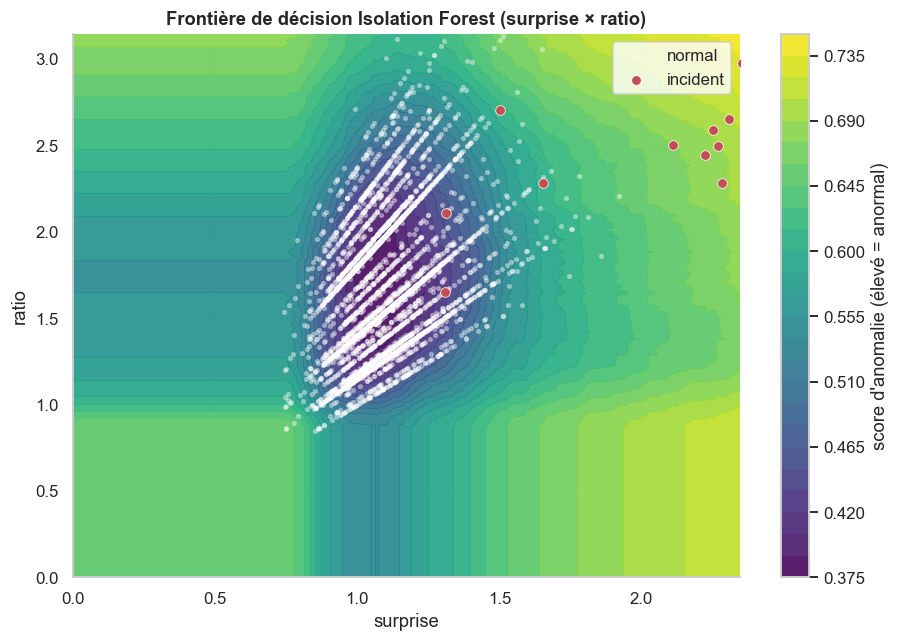

In [8]:
f2 = ["surprise", "ratio"]
X2 = F[f2].to_numpy()
iff2 = IsolationForest(contamination=contam, random_state=42, n_estimators=300).fit(X2)
xr, yr = (0, np.percentile(X2[:, 0], 99)), (0, np.percentile(X2[:, 1], 99))
xx, yy = np.meshgrid(np.linspace(*xr, 220), np.linspace(*yr, 220))
Z = -iff2.score_samples(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(8.5, 6))
cs = ax.contourf(xx, yy, Z, levels=25, cmap=SEQ, alpha=.9)
plt.colorbar(cs, ax=ax, label="score d'anomalie (élevé = anormal)")
ax.scatter(X2[y == 0, 0], X2[y == 0, 1], s=6, c="white", alpha=.35, label="normal")
ax.scatter(X2[y == 1, 0], X2[y == 1, 1], s=40, c=INCIDENT, edgecolor="white", linewidth=.5, label="incident")
ax.set_xlim(*xr); ax.set_ylim(*yr); ax.set_xlabel("surprise"); ax.set_ylabel("ratio")
ax.set_title("Frontière de décision Isolation Forest (surprise × ratio)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/04_frontiere_2d.png", bbox_inches="tight"); plt.show()

**B2 — Autre coupe (`nb_montees` × `ratio`).** Ici on « voit » comment la **surcharge** (beaucoup de montées, ratio ~normal) devient anormale — un axe qu'un simple seuil sur le ratio ignore.

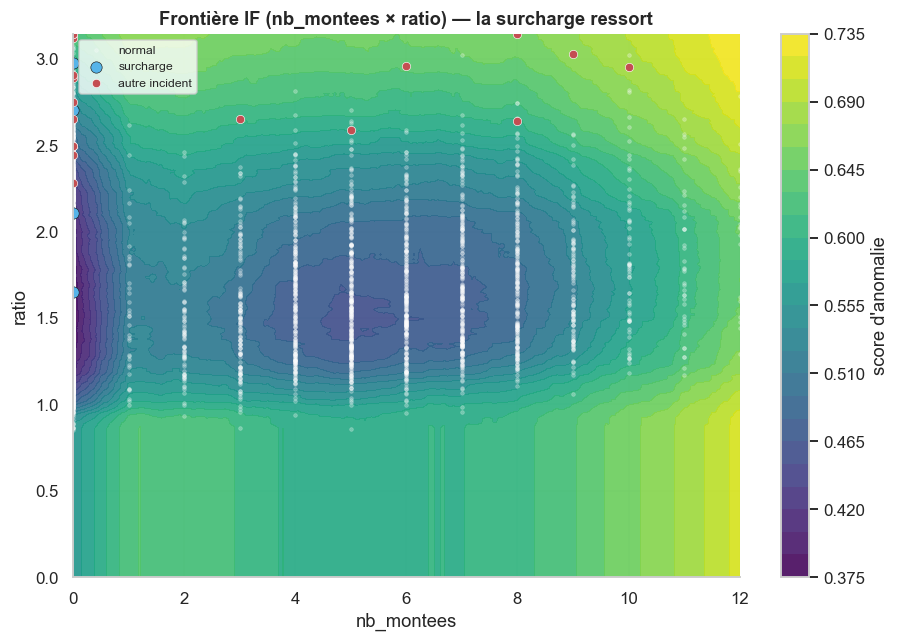

In [9]:
f2 = ["nb_montees", "ratio"]
X2 = F[f2].to_numpy()
iff2 = IsolationForest(contamination=contam, random_state=42, n_estimators=300).fit(X2)
xr, yr = (0, np.percentile(X2[:, 0], 99.5)), (0, np.percentile(X2[:, 1], 99))
xx, yy = np.meshgrid(np.linspace(*xr, 220), np.linspace(*yr, 220))
Z = -iff2.score_samples(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(8.5, 6))
cs = ax.contourf(xx, yy, Z, levels=25, cmap=SEQ, alpha=.9)
plt.colorbar(cs, ax=ax, label="score d'anomalie")
for t, mk in [("none", None), ("surcharge", "surcharge")]:
    m = (df["incident_type"] == t).to_numpy()
    ax.scatter(X2[m, 0], X2[m, 1], s=(6 if t == "none" else 55),
               c=("white" if t == "none" else OKABE["surcharge"]),
               alpha=(.3 if t == "none" else 1), edgecolor="k" if t != "none" else None,
               linewidth=.4, label=("normal" if t == "none" else "surcharge"))
m = ~np.isin(df["incident_type"].to_numpy(), ["none", "surcharge"])
ax.scatter(X2[m, 0], X2[m, 1], s=30, c=INCIDENT, edgecolor="white", linewidth=.4, label="autre incident")
ax.set_xlim(*xr); ax.set_ylim(*yr); ax.set_xlabel("nb_montees"); ax.set_ylabel("ratio")
ax.set_title("Frontière IF (nb_montees × ratio) — la surcharge ressort"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/04_frontiere_surcharge.png", bbox_inches="tight"); plt.show()

**B3 — Projection PCA du modèle curé (6D → 2D).** On projette l'espace des 6 features curées en 2D et on colore par le **score d'anomalie** du modèle complet. Les incidents (contour rouge) se retrouvent dans les zones à score élevé → le modèle les **isole** bien.

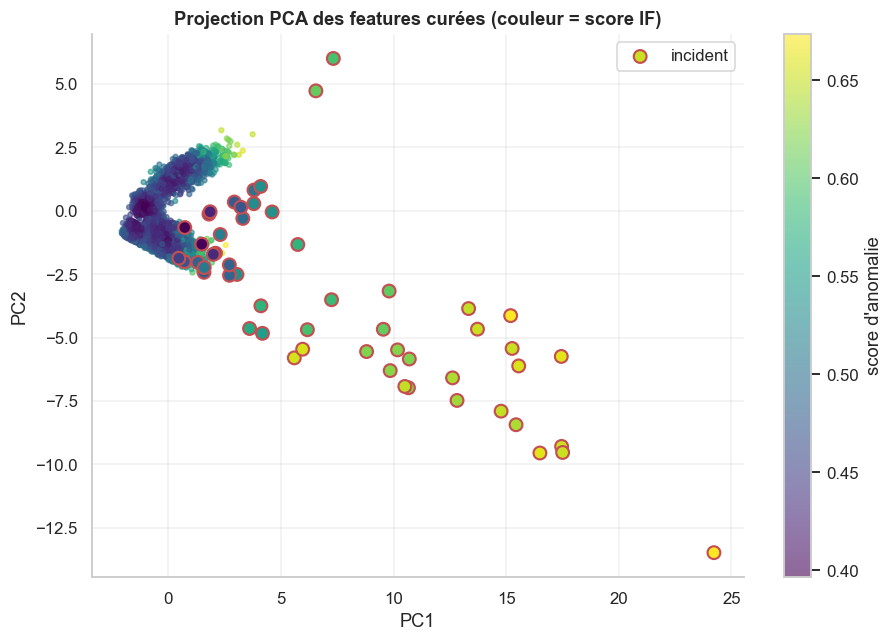

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
Xc = F[CURATED].to_numpy()
iffc = IsolationForest(contamination=contam, random_state=42, n_estimators=300).fit(Xc)
score = -iffc.score_samples(Xc)
Z = PCA(n_components=2, random_state=42).fit_transform(StandardScaler().fit_transform(Xc))
fig, ax = plt.subplots(figsize=(8.5, 6))
sc = ax.scatter(Z[y == 0, 0], Z[y == 0, 1], c=score[y == 0], cmap=SEQ, s=10, alpha=.6)
ax.scatter(Z[y == 1, 0], Z[y == 1, 1], c=score[y == 1], cmap=SEQ, s=70, edgecolor=INCIDENT, linewidth=1.4, label="incident")
plt.colorbar(sc, ax=ax, label="score d'anomalie")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("Projection PCA des features curées (couleur = score IF)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/04_pca_score.png", bbox_inches="tight"); plt.show()

**B4 — Distribution des scores d'anomalie** (normal vs incident) avec le **seuil** d'alerte. Une bonne séparation = peu de recouvrement à droite du seuil.

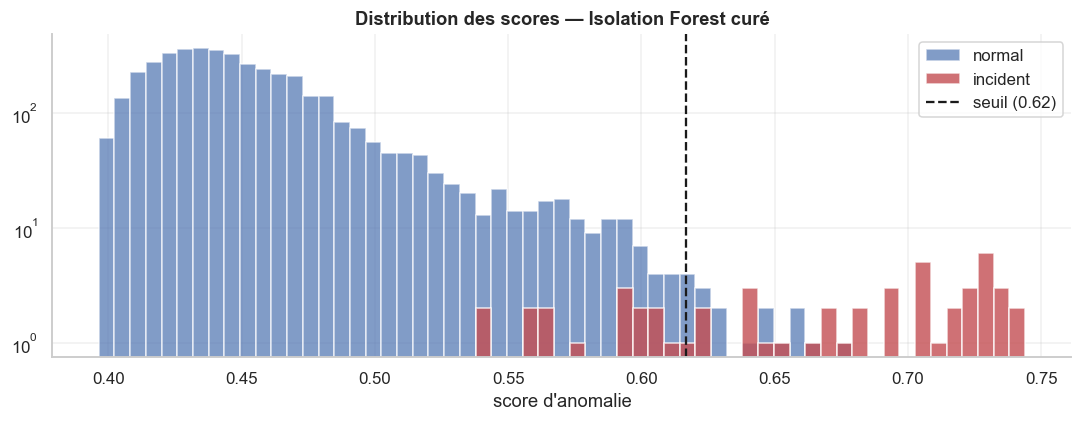

In [11]:
seuil = float(np.quantile(score, 1 - contam))
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.linspace(score.min(), score.max(), 60)
ax.hist(score[y == 0], bins=bins, color=NORMAL, alpha=.7, label="normal")
ax.hist(score[y == 1], bins=bins, color=INCIDENT, alpha=.8, label="incident")
ax.axvline(seuil, color="k", ls="--", lw=1.5, label=f"seuil ({seuil:.2f})")
ax.set_yscale("log"); ax.set_xlabel("score d'anomalie"); ax.set_title("Distribution des scores — Isolation Forest curé"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/04_scores_distribution.png", bbox_inches="tight"); plt.show()

## C. Benchmark honnête des détecteurs
**C1 — 4 détecteurs**, split temporel, budget d'alerte fixe : 2 seuils univariés vs 2 Isolation Forest (toutes features = *dilué* ; features *curées*).

In [12]:
from train_anomaly import _split_temporel, _evaluer
from anomaly import AnomalyDetector
train, test = _split_temporel(df)
ytr, yte = label_binaire(train), label_binaire(test)
cont = float(min(0.2, max(0.01, ytr.mean())))
cols_all = colonnes_all(df)
detecteurs = {
    "seuil_ratio":     AnomalyDetector("seuil_ratio", "threshold", cont, threshold_col="ratio"),
    "seuil_surprise":  AnomalyDetector("seuil_surprise", "threshold", cont, threshold_col="surprise"),
    "iforest_all":     AnomalyDetector("iforest_all", "iforest", cont, settings.seed, feature_cols=cols_all),
    "iforest_curated": AnomalyDetector("iforest_curated", "iforest", cont, settings.seed, feature_cols=CURATED),
}
scores_test, rows = {}, []
for nom, det in detecteurs.items():
    det.fit(train); s = det.scores(test); scores_test[nom] = s
    pred = s >= np.quantile(s, 1 - cont)
    m = _evaluer(yte.to_numpy(), s, pred)
    rows.append({"detecteur": nom, "PR_AUC": m["PR_AUC"], "ROC_AUC": m["ROC_AUC"], "F1": m["F1"],
                 "precision": m["precision"], "rappel": m["rappel"]})
res = pd.DataFrame(rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
res

,detecteur,PR_AUC,ROC_AUC,F1,precision,rappel
0,iforest_curated,0.9127,0.9988,0.7778,0.7000,0.875
1,seuil_surprise,0.8043,0.9867,0.6316,0.5455,0.750
2,seuil_ratio,0.7934,0.9407,0.6667,0.6000,0.750
3,iforest_all,0.4818,0.9754,0.4444,0.4000,0.500


**C2 — Comparaison visuelle (PR-AUC).** Barres annotées ; le détecteur curé domine.

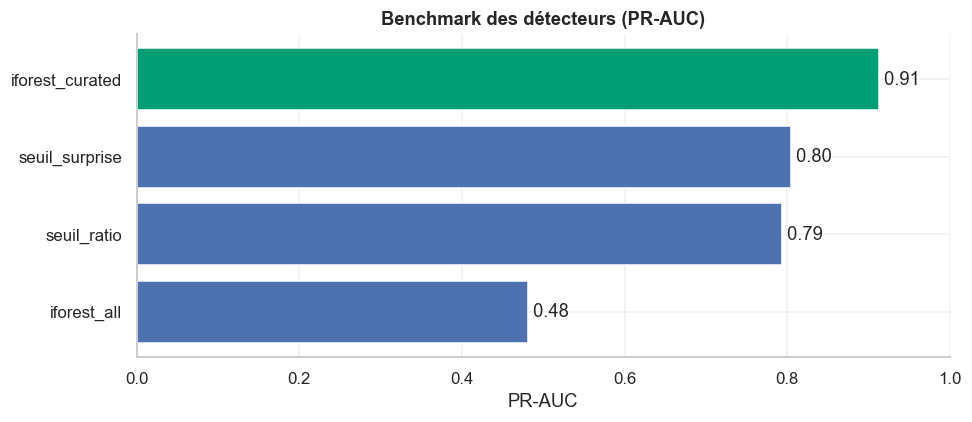

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
colr = ["#009E73" if n == "iforest_curated" else "#4C72B0" for n in res["detecteur"]]
b = ax.barh(res["detecteur"], res["PR_AUC"], color=colr); ax.invert_yaxis()
ax.set_xlabel("PR-AUC"); ax.set_title("Benchmark des détecteurs (PR-AUC)"); ax.set_xlim(0, 1)
for bar, v in zip(b, res["PR_AUC"]): ax.text(v, bar.get_y() + bar.get_height()/2, f" {v:.2f}", va="center")
plt.tight_layout(); plt.savefig(f"{FIG}/04_benchmark_prauc.png", bbox_inches="tight"); plt.show()

**C3 — Courbes ROC & Précision-Rappel** (indépendantes du seuil).

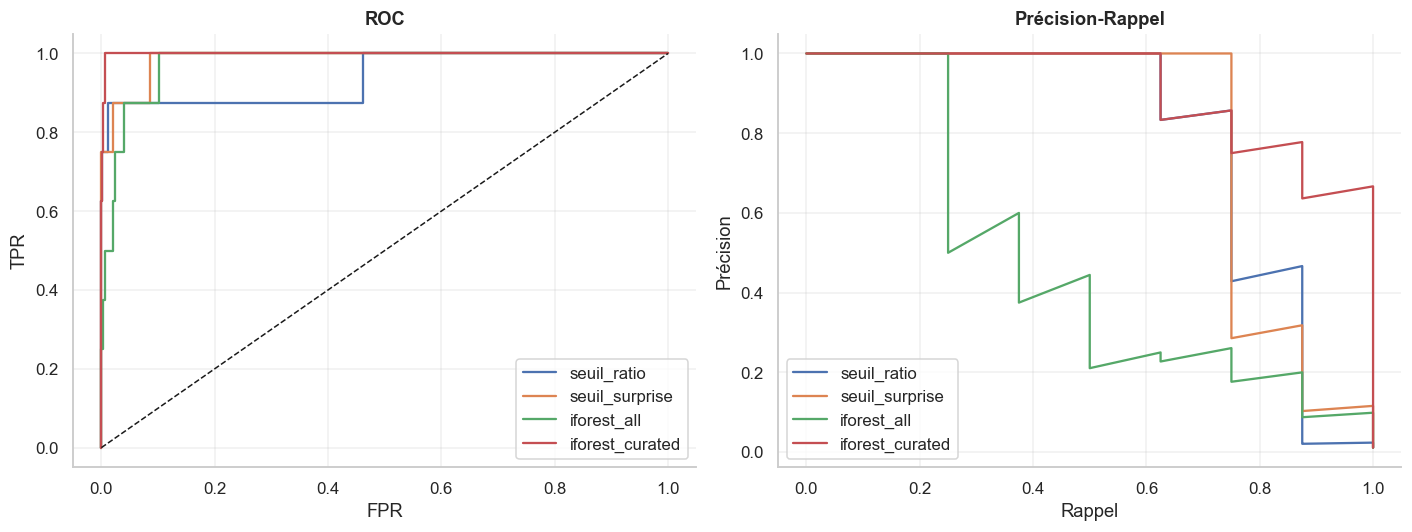

In [14]:
from sklearn.metrics import roc_curve, precision_recall_curve
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nom, s in scores_test.items():
    fpr, tpr, _ = roc_curve(yte, s); ax[0].plot(fpr, tpr, label=nom)
    prec, rec, _ = precision_recall_curve(yte, s); ax[1].plot(rec, prec, label=nom)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_title("ROC"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend()
ax[1].set_title("Précision-Rappel"); ax[1].set_xlabel("Rappel"); ax[1].set_ylabel("Précision"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{FIG}/04_courbes_roc_pr.png", bbox_inches="tight"); plt.show()

**C4 — Matrice de confusion du gagnant** (budget d'alerte fixe).

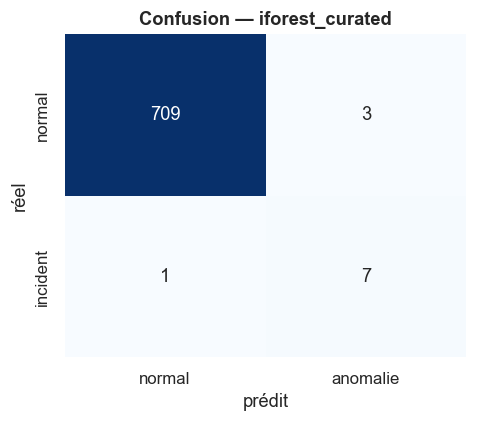

Gagnant : iforest_curated


In [15]:
from sklearn.metrics import confusion_matrix
best = res.iloc[0]["detecteur"]; s = scores_test[best]
pred = s >= np.quantile(s, 1 - cont)
fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(confusion_matrix(yte, pred), annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["normal", "anomalie"], yticklabels=["normal", "incident"], ax=ax)
ax.set_title(f"Confusion — {best}"); ax.set_xlabel("prédit"); ax.set_ylabel("réel")
plt.tight_layout(); plt.savefig(f"{FIG}/04_confusion.png", bbox_inches="tight"); plt.show()
print("Gagnant :", best)

## D. Interprétation & gel
**Triple leçon (honnête) :** (1) le **feature engineering** prime (`surprise` contextuelle) ; (2) la
**curation** prime (`iforest_curated` ≫ `iforest_all` dilué) ; (3) le **multivarié gagne** car les anomalies
sont **hétérogènes**. On gèle le gagnant (artefact servi par MS11).

In [16]:
import train_anomaly
train_anomaly.main()
cfg = json.load(open(settings.config_path, encoding="utf-8"))
print(json.dumps({k: cfg[k] for k in ["detecteur","kind","feature_cols","threshold","metrics_test","taux_incidents_%"]},
                 indent=2, ensure_ascii=False))

[MS11] 4320 trajets | train=3600 test=720 | incidents train=1.28% | contamination=0.013
  seuil_ratio        PR-AUC=0.793 ROC-AUC=0.941 F1=0.667 (P=0.60 R=0.75)
  seuil_surprise     PR-AUC=0.804 ROC-AUC=0.987 F1=0.632 (P=0.55 R=0.75)


  iforest_all        PR-AUC=0.482 ROC-AUC=0.975 F1=0.444 (P=0.40 R=0.50)


  iforest_curated    PR-AUC=0.913 ROC-AUC=0.999 F1=0.778 (P=0.70 R=0.88)

[MS11] 🏆 Gagnant : iforest_curated


[MS11] Artefacts : data/anomaly_model.pkl | data/anomaly_config.json | data/anomaly_benchmark.json
{
  "detecteur": "iforest_curated",
  "kind": "iforest",
  "feature_cols": [
    "surprise",
    "ratio",
    "dwell",
    "nb_montees",
    "nb_descentes",
    "taux_occupation"
  ],
  "threshold": 0.6145276552899578,
  "metrics_test": {
    "ROC_AUC": 0.9988,
    "PR_AUC": 0.9127,
    "precision": 0.7,
    "rappel": 0.875,
    "F1": 0.7778,
    "confusion": [
      [
        709,
        3
      ],
      [
        1,
        7
      ]
    ]
  },
  "taux_incidents_%": 1.25
}


### Conclusion
Détecteur gelé (`anomaly_model.pkl`) servi par **MS11** (`/api/analytique/anomalies`, `/scan`). Boucle DS : les incidents que l'ETA (MS12) ne peut pas prédire sont ceux que MS11 isole.